##### Advanced Statistical Analysis and Model-Based Learning (Fall 2026-2027)
# Home Assignment 2

#### Topics:
- Probability review
- Normal, Chi-Squared, t, and F distributions
- Distributional Properties of the Linear Model
- Solving LS using SVD

#### Due: 23/11/2026 by 18:30


#### Instructions:
- Write your IDs and date at the top cell.
- Submit a copy of this notebook with code filled in the relevant places as the solution of coding exercises.
- For theoretic exercises, you can either write your solution in the notebook using $\LaTeX$ (preffered) or submit additional notes.


**ID1**: 342681004 

**ID2**: 207884883

**Date**: XX.11.2026

<hr>
<hr>

## Problem 1 (Conditional Expectation)
Let $X$ and $Y$ be two random variables with a probability model $P_{X,Y}$. Let $m : \mathbb R \to \mathbb R$ such that $m(X)$ and $f(X)$ are random variables with finite variance. Suppose that $m(X)$ satisfies the ``orthogonality principle``: for any function $f : \mathbb R \to \mathbb R$ such that $f(X)$ is a random variable,
$$
\mathbb E \left[\left(Y - m(X) \right) f(X) \right] = 0.
$$
Namely, the error in predicting the target is ``orthogonal`` to the data. Prove that
$$
\mathbb E \left[\left(Y - m(X) \right)^2 \right] \leq \mathbb E \left[ \left(Y - f(X) \right)^2 \right].
$$

**Answer**:

**Reminder:** The orthogonality principle states that the best or optimal approximation of a target with a subspace occurs when the error vector is perpendicular /  orthogonal to every vector in that subspace.

Let's first develop the expression $Y-f(X)$. This expression is equivalent to $(Y-m(x)) + (m(x)- f(x))$.
If we apply the same development to $E[(Y-f(X))^2]$ we get:
$$
\begin{align*}
E[(Y-f(X))^2]   &= E[((Y-m(x)) + (m(x)- f(x)))^2] \\
                &= E[(Y-m(X))^2 + (m(X)-f(X))^2 - 2(Y-m(X))(m(X)-f(X))] \\
                &= E[(Y-m(X))^2] + E[(m(X)-f(X))^2] - 2E[(Y-m(X))(m(X)-f(X))] 
\end{align*}
$$
by linearity of expectations.


Let's define $g(X) = m(X) - f(X)$. 

Since m(X) and f(X) are random variables, g(X) is also a random variable. Applying the orthogonality principle to g gives $E[(Y-m(X))(m(X)-f(X))] = E[(Y-m(X))g(X)] = 0$.

Thus: $E[(Y-f(X))^2] = E[(Y-m(X))^2] + E[(m(X)-f(X))^2]$

Since $(m(X)-f(X))^2 \geq 0$ everywhere, monotonicity of expectation ensures that $E[(m(X) - f(X))^2] \geq 0$. Dropping this non-negative term gives
$$E[(Y - m(X))^2] \leq E[(Y - f(X))^2]$$
with equality holding if and only if $f(X) = m(X)$ almost surely.

# Problem 2 (Sampling from $\mathcal N(0,1)$, $\chi^2$, $t$, and $F$)
In the following exercise, you can only sample using repeated calls to ``random.random()``.
You can use the ``scipy.stats`` package *only* to illustrate PDFs. You should illustrate histograms with number of bins about 5%-10% of the number of samples $n=1,000$ in the input to the histogram. For example, use $100$ bins equally spaced between the range of the samples, so that you'll get a nice comparison between the empirical distribution and the theoretical distribution represented by the PDF. Make sure that the histogram is normalized to approximate the density of the simulated random variable. Set the seed ``random.seed(my_id)`` where ``my_id`` is your ID number with leading zeros removed.

1. Implement the functions ``sample_unif``, ``sample_normal_clt``, and ``sample_normal``. Illustrate the histogram of $1000$ samples from ``sample_normal_clt`` and $1000$ samples from ``sample_normal``. Choose the input to ``sample_normal_clt`` so that the two histogram look alike.
2. Implement the functions ``sample_chisq``, ``sample_t``, and ``sample_f``. You should use ``sample_normal`` repeatedly.
3. Use ``sample_normal`` to sample $1000$ times from $\mathcal N(0,1)$ and use one figure to illustrate the histogram of the samples and the true PDF of $\mathcal N(0,1)$
4. Use ``sample_chisq`` to sample $1000$ times from $\chi^2_k$ and use one figure to illustrate the histogram of the samples and the true PDF of $\chi^2_k$; for $k=4$ and $k=12$.
5. Use ``sample_t`` to sample $1000$ times from $t_k$ (the $t$-distribution with $k$ degrees of freedom) and use one figure to illustrate the histogram of the samples and the true PDF of $t_k$; for $k=4$ and $k=12$.
6. Use ``sample_F`` to sample $1000$ times from $F_{k_1,k_2}$ and use one figure to illustrate the histogram of the samples and the true PDF of $F_{k_1,k_2}$; for $(k_1, k_2)= (8,6)$ and $(k_1, k_2)= (40,35)$.

In [1]:
import random
from scipy.stats import norm
import numpy as np

def sample_unif(n: int) -> list[float]:
    """
    n independent samples from the uniform distribution over (0,1)
    """

    # YOUR CODE HERE
    samples = [random.random() for i in range(n)]
    return samples


def sample_normal_clt(n: int) -> float:
    """
    Use the CLT to approximately sample from the standard normal distribution

    Args:
        n:    number of samples from a non-normal distribution

    Returns:
        z:    a random sample, approximately from the standard normal distribution

    """

    # YOUR CODE HERE
    samples = sample_unif(n)
    return float(np.sqrt(12 * n) * (np.mean(samples) - 0.5))

def sample_normal() -> float:
    """
    Sample from the standard normal distribution using a single sample
    from the uniform distribution. You should use the normal quantile function
    ``norm.ppf``

    Return:
        z:    a random sample from the standard normal distribution

    """

    # YOUR CODE HERE
    u = random.random()
    while u == 0:
        u = random.random()
    return float(norm.ppf(u))


def sample_chisq(k: int) -> float:
    """
    Sample from the chisquared distribution with k degrees of freedom

    Args:
        k:    number of degrees of freedom (DoF)

    Return:
        x:    random sample from the chisquared distribution with k degrees of freedom

    """

    # YOUR CODE HERE
    samples = sum(sample_normal()**2 for i in range(k))
    return float(samples)


def sample_t(k: int) -> float:
    """
    Sample from the t distribution with k degrees of freedom

    Args:
        k:    number of degrees of freedom

    Return:
        x:    random sample from the t distribution

    """

    # YOUR CODE HERE
    #numerator = [sample_normal() for _ in range(k1)]
    numerator = sample_normal()
    denominator = np.sqrt(sample_chisq(k)/k)
    return float(numerator / denominator)


def sample_f(k1: int, k2:int) -> float:
    """
    Sample from the F distribution with k1 over k2 degrees of freedom

    Args:
        k1:    number of degrees of freedom numerator
        k2:    number of degrees of freedom denominator

    Return:
        x:    random sample from the F distribution

    """

    # YOUR CODE HERE
    numerator = sample_chisq(k1) / k1
    denominator = sample_chisq(k2) / k2
    return float(numerator / denominator)

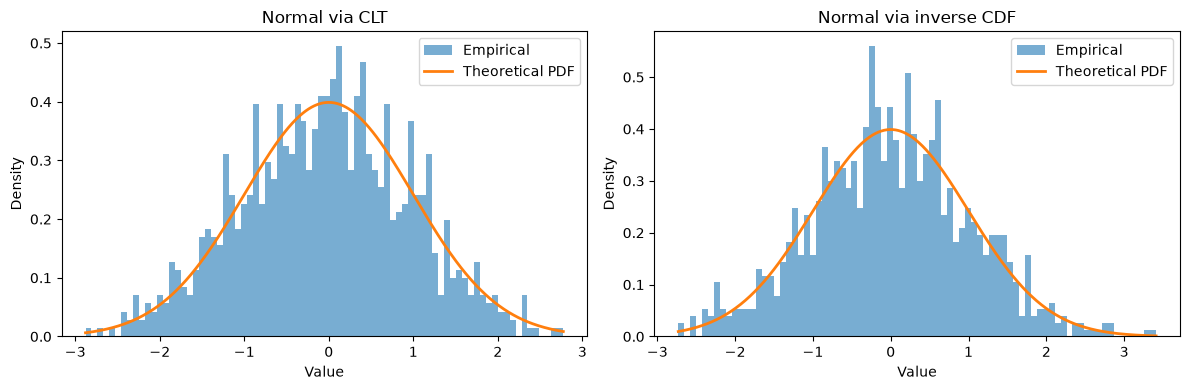

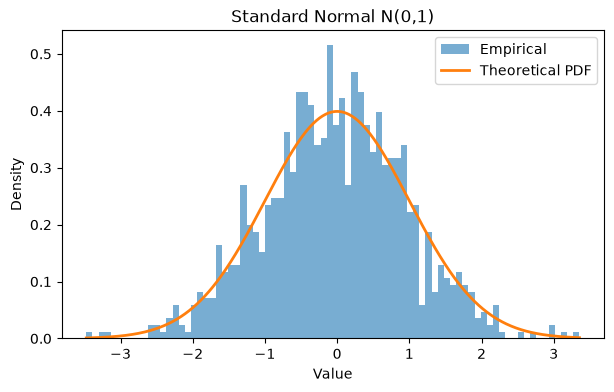

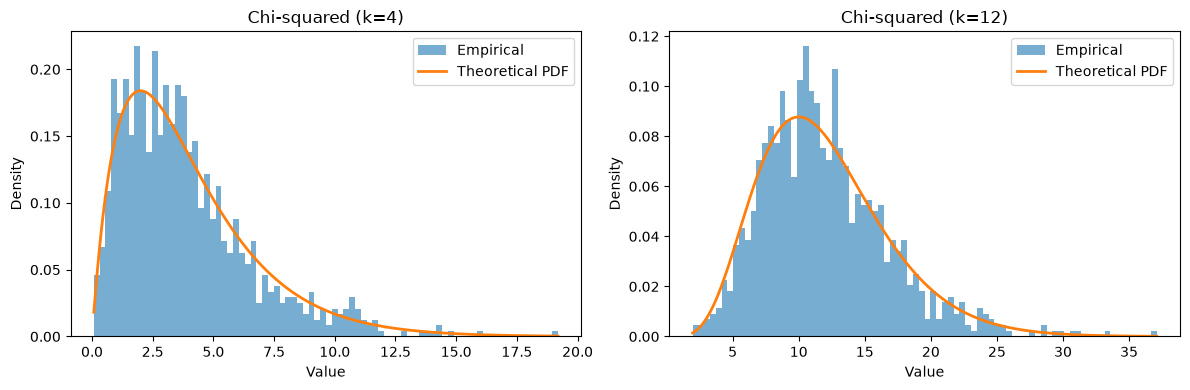

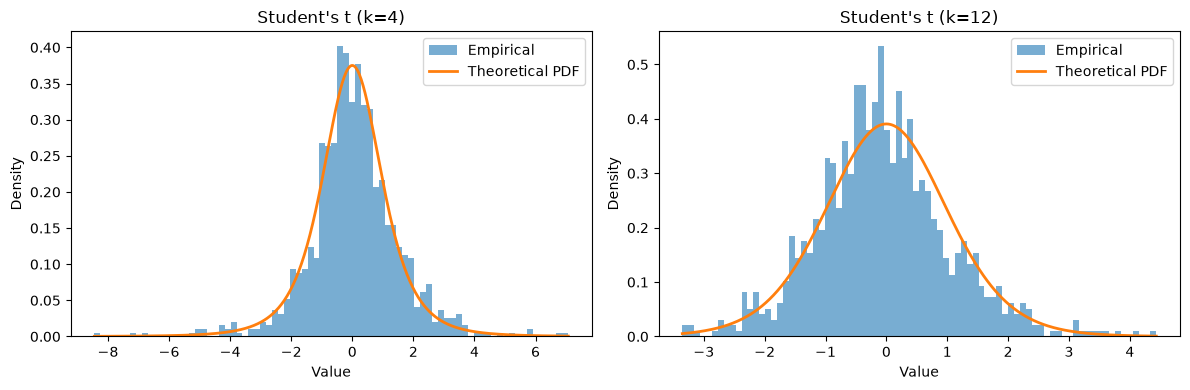

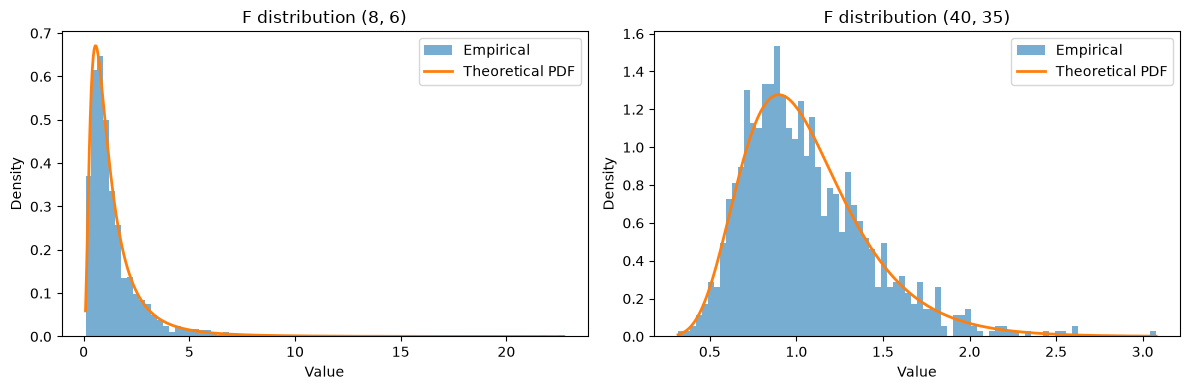

In [2]:
MY_ID = 342681004 # your personal ID number with leading zeros removed
random.seed(MY_ID)

# Your code to items 2-4 goes here:

import matplotlib.pyplot as plt
from scipy.stats import norm, chi2, t, f


def plot_distribution(samples, pdf, title, ax):
    bins = np.linspace(min(samples), max(samples), 81)
    x = np.linspace(min(samples), max(samples), 500)

    ax.hist(samples, bins=bins, density=True,
            alpha=0.6, label="Empirical")
    ax.plot(x, pdf(x), linewidth=2, label="Theoretical PDF")

    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()


# Part 1: Compare CLT-based sampling with inverse transform
n_clt = 100

clt_samples = [sample_normal_clt(n_clt) for _ in range(1000)]
normal_samples = [sample_normal() for _ in range(1000)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, samples, title in zip(
    axes,
    [clt_samples, normal_samples],
    ["Normal via CLT", "Normal via inverse CDF"]
):
    plot_distribution(samples, norm.pdf, title, ax)

plt.tight_layout()
plt.show()


# Part 3: Standard normal
samples = [sample_normal() for _ in range(1000)]

fig, ax = plt.subplots(figsize=(7, 4))
plot_distribution(samples, norm.pdf, "Standard Normal N(0,1)", ax)
plt.show()


# Part 4: Chi-squared, k=4 and k=12
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, k in zip(axes, [4, 12]):
    samples = [sample_chisq(k) for _ in range(1000)]
    plot_distribution(samples, chi2(k).pdf, f"Chi-squared (k={k})", ax)

plt.tight_layout()
plt.show()


# Part 5: Student's t, k=4 and k=12
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, k in zip(axes, [4, 12]):
    samples = [sample_t(k) for _ in range(1000)]
    plot_distribution(samples, t(k).pdf, f"Student's t (k={k})", ax)

plt.tight_layout()
plt.show()


# Part 6: F distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (k1, k2) in zip(axes, [(8, 6), (40, 35)]):
    samples = [sample_f(k1, k2) for _ in range(1000)]
    plot_distribution(
        samples, f(k1, k2).pdf,
        f"F distribution ({k1}, {k2})", ax
    )

plt.tight_layout()
plt.show()


## Problem 3 (The Normal Distribution)

1. Let $Z = (Z_1,\ldots,Z_9)^\top \sim \mathcal N(\mu, I_9)$ where $\mu \in \reals^9$. Show that $3Z_1-Z_2+Z_3-Z_4$ is independent of $Z_1 + Z_2 - Z_3 + Z_4 - Z_5$.

2. Suppose that $Z \sim \mathcal N(\mu, I_n)$ and let $X = a^\top Z$ and $Y = B^\top Z$ for a non-random vectors $a \in \mathbb R^n$ and a non-random matrix $B \in \mathbb R^{n \times p}$. Find conditions on $a$ and $B$ such that $X$ is independent of $Y$.

3. Suppose that $Z_{ij} \overset{iid}{\sim} \mathcal N(0, 1)$ for $i= 1,\ldots,I$ and $j=1,\ldots,J$. Define
$$
\bar{Z}_{i\bullet} := \frac{1}{J} \sum_{j=1}^J Z_{ij},\qquad \bar{Z}_{\bullet j} := \frac{1}{I} \sum_{i=1}^I Z_{ij}, \qquad \bar{Z}_{\bullet \bullet} := \frac{1}{IJ} \sum_{j=1}^J \sum_{i=1}^I Z_{ij}
$$

- Is $\bar{Z}_{i\bullet}$ independent of $\bar{Z}_{\bullet j}$ ?
- Is $\bar{Z}_{1\bullet}$ independent of $\bar{Z}_{2\bullet}$ ?
- Is $\bar{Z}_{i\bullet} - \bar{Z}_{\bullet \bullet}$ independent of $\bar{Z}_{i\bullet}$ ?

4. Consider the variance-covariance matrix
$$
\bar{\Sigma} = \begin{bmatrix} 1 & 0.4 \\
0.4 & 1
\end{bmatrix}
$$
Using as many samples as you need from the standard normal distribution (e.g. ``numpy.random.randn``), generate $N = 1000$ independent samples from the bivariate normal distribution $\mathcal N(0, \bar{\Sigma})$ (you'll get $N$ pairs). Illustrate these samples over a scatter plot.

5. Consider the region in $\reals^2$:
$$
A = \{ (x,y)\,: 0 \leq x \leq 1, 2x \leq y \leq 3\}
$$
For $(X_1, X_2) \sim \mathcal N(0, \bar{\Sigma})$, estimate
$$
\Pr\left[ (X_1, X_2) \in A \right]
$$
in two ways:
    1. Evaluating the integral over the Gaussian density function **numerically**. Set the number of grid points $G$ in every axis to be at least $500$.
    2. Estimating the fraction of samples in 4 that falls in the region $A$


**ANSWERS**:

**1. Independence of the two linear combinations**

Let $U=3Z_1-Z_2+Z_3-Z_4$ and $V=Z_1+Z_2-Z_3+Z_4-Z_5$. Their coefficient vectors are
$$
a=(3,-1,1,-1,0,0,0,0,0)^\top,
\qquad b=(1,1,-1,1,-1,0,0,0,0)^\top.
$$
Thus $U=a^\top Z$ and $V=b^\top Z$. Since $\operatorname{Cov}(Z)=I_9$,
$$
\operatorname{Cov}(U,V)=a^\top I_9b=a^\top b=3-1-1-1=0.
$$
The pair $(U,V)$ is jointly Gaussian because it is a linear transformation of the Gaussian vector $Z$. For jointly Gaussian variables, zero covariance implies independence, so **$U$ and $V$ are independent**. The value of $\mu$ does not affect this conclusion.

**2. Conditions on $a$ and $B$**

The vector $(X,Y^\top)^\top$ is jointly Gaussian, with cross-covariance
$$
\operatorname{Cov}(X,Y)=a^\top\operatorname{Cov}(Z)B=a^\top B\in\mathbb R^{1\times p}.
$$
Therefore the necessary and sufficient condition is
$$
\boxed{X\perp\!\!\!\perp Y\quad\Longleftrightarrow\quad a^\top B=0_{1\times p}
\quad\Longleftrightarrow\quad B^\top a=0_p.}
$$
Equivalently, $a$ must be orthogonal to every column of $B$, or $a\in\operatorname{Null}(B^\top)$. No full-rank assumption on $B$ is needed.

**3. Independence of the sample means**

All the means and differences below are jointly Gaussian, because they are linear combinations of the independent normal observations. Their covariance must be calculated: linear combinations of independent observations can share observations and need not have zero covariance.

- **$\bar Z_{i\bullet}$ and $\bar Z_{\bullet j}$ are not independent.** We have
  $$
  \operatorname{Cov}(\bar Z_{i\bullet},\bar Z_{\bullet j})
  =\frac{1}{IJ}\sum_{k=1}^J\sum_{\ell=1}^I
  \operatorname{Cov}(Z_{ik},Z_{\ell j})=\frac{1}{IJ}>0.
  $$
  Only the term with $k=j$ and $\ell=i$ is nonzero; it is $\operatorname{Var}(Z_{ij})=1$.

- **$\bar Z_{1\bullet}$ and $\bar Z_{2\bullet}$ are independent** (assuming $I\geq2$ so both rows exist). They involve disjoint sets of independent observations, and
  $$
  \operatorname{Cov}(\bar Z_{1\bullet},\bar Z_{2\bullet})
  =\frac{1}{J^2}\sum_{j=1}^J\sum_{k=1}^J
  \operatorname{Cov}(Z_{1j},Z_{2k})=0.
  $$
  Joint Gaussianity then implies independence.

- **$\bar Z_{i\bullet}-\bar Z_{\bullet\bullet}$ and $\bar Z_{i\bullet}$ are not independent when $I>1$.** First,
  $$
  \operatorname{Var}(\bar Z_{i\bullet})=\frac{1}{J},\qquad
  \bar Z_{\bullet\bullet}=\frac{1}{I}\sum_{\ell=1}^I\bar Z_{\ell\bullet}.
  $$
  Since different row means are independent,
  $$
  \operatorname{Cov}(\bar Z_{\bullet\bullet},\bar Z_{i\bullet})
  =\frac{1}{I}\operatorname{Var}(\bar Z_{i\bullet})=\frac{1}{IJ}.
  $$
  Hence
  $$
  \boxed{\operatorname{Cov}(\bar Z_{i\bullet}-\bar Z_{\bullet\bullet},\bar Z_{i\bullet})
  =\frac{1}{J}-\frac{1}{IJ}=\frac{I-1}{IJ}.}
  $$
  This is positive for $I>1$, so the variables are dependent. In the special case $I=1$, the difference is identically zero and is independent of the row mean.


**4. Generate and plot 1,000 bivariate normal samples**

A Cholesky factor of $\bar\Sigma$ is
$$
L=\begin{bmatrix}1&0\\0.4&\sqrt{1-0.4^2}\end{bmatrix},
\qquad LL^\top=\bar\Sigma.
$$
For independent $U,V\sim\mathcal N(0,1)$, set
$$
X_1=U,\qquad X_2=0.4U+\sqrt{0.84}\,V.
$$
This is a Gaussian vector with mean zero, both marginal variances equal to one, and covariance $0.4$. Independent standard normal pairs give independent samples. The code uses a fixed seed for reproducibility; it also marks which samples fall in the region from part 5.


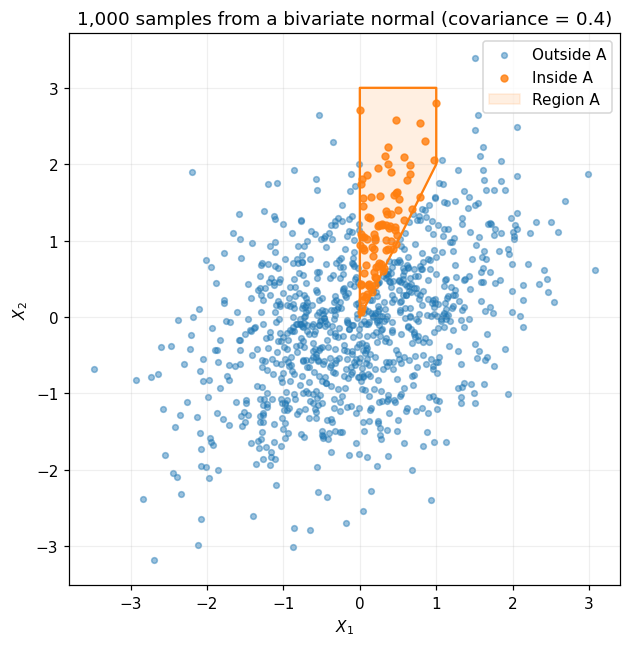

Sample mean: [-0.03537701 -0.00909034]
Sample covariance matrix:
 [[1.07867122 0.41578971]
 [0.41578971 0.99778291]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng_q3 = np.random.default_rng(342681004)
N = 1000
Sigma_q3 = np.array([[1.0, 0.4], [0.4, 1.0]])
L_q3 = np.linalg.cholesky(Sigma_q3)
standard_normals_q3 = rng_q3.standard_normal((N, 2))
samples_q3 = standard_normals_q3 @ L_q3.T
x1_q3, x2_q3 = samples_q3.T

in_A_q3 = (
    (x1_q3 >= 0) & (x1_q3 <= 1)
    & (x2_q3 >= 2 * x1_q3) & (x2_q3 <= 3)
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(x1_q3[~in_A_q3], x2_q3[~in_A_q3],
           s=14, alpha=0.45, label="Outside A")
ax.scatter(x1_q3[in_A_q3], x2_q3[in_A_q3],
           s=20, alpha=0.8, color="tab:orange", label="Inside A")
ax.fill([0, 1, 1, 0], [0, 2, 3, 3], color="tab:orange",
        alpha=0.12, label="Region A")
ax.plot([0, 1, 1, 0, 0], [0, 2, 3, 3, 0],
        color="tab:orange", linewidth=1.5)
ax.set(xlabel=r"$X_1$", ylabel=r"$X_2$",
       title="1,000 samples from a bivariate normal (covariance = 0.4)")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

print("Sample mean:", samples_q3.mean(axis=0))
print("Sample covariance matrix:\n", np.cov(samples_q3, rowvar=False))


**5. Estimate $\Pr[(X_1,X_2)\in A]$ in two ways**

The density is
$$
f(x,y)=\frac{1}{2\pi\sqrt{0.84}}
\exp\!\left(-\frac{x^2-0.8xy+y^2}{2(0.84)}\right),
$$
so the required probability is
$$
p=\int_0^1\int_{2x}^{3}f(x,y)\,dy\,dx.
$$

1. **Numerical integration:** use $G=1001\geq500$ grid points for $x\in[0,1]$. For each $x$, use $G$ grid points for $y\in[2x,3]$, and apply the trapezoidal rule first in $y$ and then in $x$. Matching the inner grid to the sloping boundary integrates over the specified region directly.
2. **Sample fraction:** use the same $N=1000$ samples generated in part 4 and calculate
   $$
   \widehat p_{\mathrm{MC}}=\frac{1}{1000}\sum_{r=1}^{1000}
   \mathbf{1}\{0\leq X_1^{(r)}\leq1,\;2X_1^{(r)}\leq X_2^{(r)}\leq3\}.
   $$
   Its estimated Monte Carlo standard error is $\sqrt{\widehat p_{\mathrm{MC}}(1-\widehat p_{\mathrm{MC}})/1000}$, which explains why it need not equal the numerical integral exactly.


In [2]:
from scipy.integrate import trapezoid

G = 1001
x_grid_q3 = np.linspace(0.0, 1.0, G)
t_grid_q3 = np.linspace(0.0, 1.0, G)
# Each column contains G y values from 2*x to 3 for a fixed x.
y_grid_q3 = (
    2 * x_grid_q3[None, :]
    + (3 - 2 * x_grid_q3[None, :]) * t_grid_q3[:, None]
)
x_mesh_q3 = x_grid_q3[None, :]
density_q3 = np.exp(
    -(x_mesh_q3**2 - 0.8 * x_mesh_q3 * y_grid_q3 + y_grid_q3**2)
    / (2 * 0.84)
) / (2 * np.pi * np.sqrt(0.84))

integral_y_q3 = trapezoid(density_q3, x=y_grid_q3, axis=0)
p_grid_q3 = trapezoid(integral_y_q3, x=x_grid_q3)
count_A_q3 = np.count_nonzero(in_A_q3)
p_mc_q3 = count_A_q3 / N
mc_se_q3 = np.sqrt(p_mc_q3 * (1 - p_mc_q3) / N)

print(f"Numerical integral (G = {G} per axis): {p_grid_q3:.8f}")
print(f"Sample fraction: {count_A_q3}/{N} = {p_mc_q3:.6f}")
print(f"Estimated Monte Carlo standard error: {mc_se_q3:.6f}")
print(f"Absolute difference between estimates: {abs(p_mc_q3 - p_grid_q3):.6f}")


Numerical integral (G = 1001 per axis): 0.08058161
Sample fraction: 88/1000 = 0.088000
Estimated Monte Carlo standard error: 0.008959
Absolute difference between estimates: 0.007418


For this fixed seed, the numerical integral is **0.08058161**, while the sample fraction is **88/1000 = 0.088**. The Monte Carlo standard error is approximately **0.0090**. The estimates differ by about **0.83** estimated standard errors, which is consistent with sampling variation.


## Problem 4 (Conditional Distribution)
For
$$
\begin{bmatrix}
X \\
Y \\
Z
\end{bmatrix} \sim \mathcal N\left( \begin{bmatrix} 1 \\
2\\
3
\end{bmatrix}, \begin{bmatrix}
 4 & -1 & 3 \\
 -1 & 2 & -3 \\
 3 & -3 & 8
\end{bmatrix}
\right)
$$
find (numerically):
1. The distribution of $X$ given that $Y = 1$.
2. The joint distribution of $X$ and $Y$ given $Z = 1$.
3. The distribution of $Y$ given that $Z = 2$ and $X = 3$.
4. $Pr(Y \in [-1,1] | Z=4, X=3)$
<hr>
<hr>

## Problem 5 (Distributional Properties of the Least Squares Estiamte)
Consider a least squares model with one predictor $p=1$ without an intercept term, i.e. $y_i = \beta x_i + \epsilon_i$, $i=1,\ldots,n$.
1. Write the least squares solution $\hat{\beta} \in \mathbb R$ in terms of $x = (x_1,\ldots,x_n)^\top$ and $y = (y_1,\ldots,y_n)^\top$.
2. With $\hat{y}_i = \hat{\beta} x_i$ and $\hat{\epsilon}_i = y_i - \hat{y}_i$, show that
 - $\sum_{i=1}^n \hat{y}_i \hat{\epsilon}_i = 0$
 - $\|\hat{\epsilon}\|^2 = \|y\|^2 -  \|\hat{y}\|^2$
3. Suppose that $\epsilon_i \overset{iid}{\sim} N(0, 1)$.
 - What is the distribution of the random vector $[ \hat{\epsilon}~~ \hat{y}]^\top$?
 - What is the distribution of the random vector $[\hat{y}~~ \hat{\beta}]^\top$?
4. (bonus) Set $\|\epsilon\|_{\infty} := \max_{i=1,\ldots,n} |\epsilon_i|$. What is $Pr( \|\hat{\epsilon}\|_{\infty} > 2)$? is it larger or smaller than $Pr(\|\epsilon\|_{\infty}  > 2)$? (The point: we want to know if the predicted residuals tend to have less or more extreme values than the true ones)

<hr>
<hr>


## Problem 6 (Model fitting, t- and F-Tests)
Consider the house prices dataset from the EDA notebook, which you can obtain from kaggle via:

In [ ]:
!kaggle competitions download -c house-prices-advanced-regression-techniques
!mkdir house-prices
!unzip house-prices-advanced-regression-techniques.zip -d house-prices/

100%|█████████████████████████████████████████| 199k/199k [00:00<00:00, 399kB/s]
100%|█████████████████████████████████████████| 199k/199k [00:00<00:00, 398kB/s]
Archive:  house-prices-advanced-regression-techniques.zip
  inflating: house-prices/data_description.txt  
  inflating: house-prices/sample_submission.csv  
  inflating: house-prices/test.csv   
  inflating: house-prices/train.csv  


Only consider houses of lot size smaller than $15,000$ square feet, e.g. by using

In [ ]:
import pandas as pd
data_raw = pd.read_csv("house-prices/train.csv")
data = data_raw[data_raw.LotArea < 15000]  # we focus on small lots

Consider predicting ``SalePrice`` via a linear model with predictors:

In [ ]:
feat_set1 = ['LotArea',  'YearBuilt', 'YrSold', 'GarageCars',
             'FullBath', 'TotalBsmtSF', 'GarageArea', 'OverallQual']

plus a constant.

1. Find the least squares estimate $\hat{\beta}$ of this model.
2. Find $R^2$ of this model.
3. For each $\beta_j$, $j=1,\ldots,9$, evaluate the $t$ statistic corresponding to testing
$$
H_{0j}\,:\, \beta_j=0
$$
and its P-values (identify first the number of degrees of freedom).
4. Which of these statistics exceeds the $0.975$-th quantile of the corresponding $t$ distribution and below the $0.025$-th quantile? (values exceeding theses quantiles are strong evidence against $H_{0j}$)
5. Consider a smaller model involving only ``LotArea``,  ``YearBuilt``, ``YrSold`` as predictors. Find the least squares estimate of this smaller model and its sum of sqaures. Is this model provides a valid representation of the data compared to the original larger one? Answer your question by evaluating the relevant $F$ statistic and report on the F-test's P-value.

<hr>
<hr>

# Problem 7 (Solving LS using SVD)
Consider the housing prices dataset (``housing_prices.csv``). Use houses of lot size smaller than 15000 ft.

1. Find the least squares coefficient of the linear model with target variable ``SalePrice`` and the 16 predictors:
``['LotArea',  'YearBuilt',
  'GarageCars', 'YrSold', 'MoSold', 'Fireplaces',
  'HalfBath', 'LowQualFinSF', 'TotalBsmtSF',
  '1stFlrSF', 'LotFrontage', 'ScreenPorch',
   'WoodDeckSF', 'OverallCond', 'BsmtUnfSF']``
plus a constant term. Remove all entries in which one or more of these predictors is missing. Use the following methods:
 - By inverting the matrix $Z^\top Z$. Denote the solution $\hat{\beta}$.
 - Using the SVD method. Here, decide that $\sigma_i > 0$ if $\sigma_i / \sigma_1 > 10^{-6}$. Denote the solution $\hat{\beta}^{SVD}$.

Which method has the smallest $R^2$?

2. Plot $\hat{y}$ and $\hat{y}^{SVD}$ over the same pannel to convince yourself that both methods resulted in similar fitted responses.
3. Plot $\log(|\hat{\beta}_i/\hat{\beta}^{SVD}_i|)$ vs. $i$ for $i=1,\ldots,p$. Indicate the covariate whose coefficient exhibits the largest difference between the methods.

The point: When there are many predictors, it is likely that $Z$ will be rank deficient in the sense that some of its singular values are very small. Removing those singular values is usually a good practice; it is important to observe how this removal affects the solution.

You can use the code below to read and arrange the data

In [ ]:
import pandas as pd

target = 'SalePrice'
lo_predictors = ['const', 'SalePrice', 'LotArea',  'YearBuilt',
    'GarageCars', 'YrSold', 'MoSold', 'Fireplaces',
    'HalfBath', 'LowQualFinSF', 'TotalBsmtSF',
    '1stFlrSF', 'LotFrontage', 'ScreenPorch',
     'WoodDeckSF', 'OverallCond', 'BsmtUnfSF']

data = pd.read_csv("housing_prices.csv")
data = data[data.LotArea < 15000]  # we focus on small lots
data['const'] = 1                  # add constant term
data = data.filter(lo_predictors).dropna() # remove all other columns

y = data[target].values
X = data.drop(target, axis=1)
Z = X.values
n, p = Z.shape